# Proyecto Final — CallMeMaybe: identificar operadores ineficaces

**Autor:** Orlando  ·  **Programa:** Analista de Datos (TripleTen)

## De qué trata
CallMeMaybe es un servicio de telefonía virtual. Sus clientes son empresas que reparten muchas llamadas entrantes entre varios **operadores** o hacen llamadas salientes. La empresa quiere una función que ayude a los supervisores a detectar a los **operadores menos eficaces**.

## Cuándo un operador es ineficaz
Según el negocio, un operador es ineficaz si:
1. Tiene **muchas llamadas entrantes perdidas** (internas y externas).
2. Tiene un **tiempo de espera largo** en las llamadas entrantes.
3. Si se supone que debe hacer **llamadas salientes**, hace **pocas**.

## Qué voy a hacer
1. Análisis exploratorio de datos (EDA) y limpieza.
2. Crear métricas por operador e identificar a los ineficaces.
3. Probar 2 hipótesis estadísticas.
4. Preparar los datos para los dashboards y las conclusiones.

## Los datos
- `telecom_dataset_new.csv`: una fila por día/operador/tipo de llamada (dirección, si es interna, si se perdió, número y duración de llamadas).
- `telecom_clients.csv`: datos de cada empresa cliente (plan de tarifa y fecha de registro).

> **Nota:** el *tiempo de espera* no viene como columna; lo calculo como `total_call_duration - call_duration`.


## Paso 0 — Preparación
Importo las librerías y cargo los dos archivos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
# Nombres de los archivos (así se llaman los que me dieron)
DATA = 'telecom_dataset_new.csv'
CLIENTS = 'telecom_clients.csv'

# --- Si trabajas en Google Colab ---
# Sube los 2 archivos con el panel de la izquierda (icono de carpeta),
# o descomenta estas 2 líneas para subirlos desde tu compu:
# from google.colab import files
# files.upload()

df = pd.read_csv(DATA)
clientes = pd.read_csv(CLIENTS)
df.head()

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,880022.0,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022.0,True,3,0,25


## Paso 1 — Primer vistazo a los datos (EDA)
Reviso tipos de datos, tamaño, valores ausentes y duplicados.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  str    
 2   direction            53902 non-null  str    
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(1), str(2)
memory usage: 3.3+ MB


In [4]:
print('Tamaño:', df.shape)
print('\nValores ausentes por columna:')
print(df.isna().sum())
print('\nFilas duplicadas:', df.duplicated().sum())

Tamaño: (53902, 9)

Valores ausentes por columna:
user_id                   0
date                      0
direction                 0
internal                117
operator_id            8172
is_missed_call            0
calls_count               0
call_duration             0
total_call_duration       0
dtype: int64

Filas duplicadas: 4900


In [5]:
clientes.info()
clientes.head()

<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      732 non-null    int64
 1   tariff_plan  732 non-null    str  
 2   date_start   732 non-null    str  
dtypes: int64(1), str(2)
memory usage: 17.3 KB


,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16


### Lo que noto
- Hay **filas duplicadas** que tengo que quitar.
- La columna `operator_id` tiene **muchos vacíos**: son llamadas que no quedaron asignadas a un operador (varias son entrantes perdidas). Para el análisis *por operador* voy a dejar fuera esas filas, porque no puedo atribuirlas a nadie.
- `internal` tiene unos pocos vacíos.
- `date` es texto y trae zona horaria: la convierto a fecha real.


## Paso 2 — Limpieza de datos

In [6]:
# 1) Quitar filas duplicadas
df = df.drop_duplicates().reset_index(drop=True)

# 2) Convertir la fecha (trae zona horaria +03:00)
df['date'] = pd.to_datetime(df['date'], utc=True)

# 3) Rellenar los pocos 'internal' vacíos como False (llamada externa)
df['internal'] = df['internal'].fillna(False)

# 4) Crear el tiempo de espera = duración total - duración de la llamada
df['wait_time'] = df['total_call_duration'] - df['call_duration']

print('Filas después de limpiar:', df.shape)
print('Duplicados restantes:', df.duplicated().sum())
print('Tiempos de espera negativos (deberían ser 0):', (df['wait_time'] < 0).sum())

Filas después de limpiar: (49002, 10)
Duplicados restantes: 0
Tiempos de espera negativos (deberían ser 0): 0


## Paso 3 — Unir con los datos de los clientes
Pego a cada llamada el plan de tarifa de su empresa (por `user_id`), por si quiero comparar por plan.

In [7]:
df = df.merge(clientes, on='user_id', how='left')
print('Llamadas por plan de tarifa:')
df['tariff_plan'].value_counts(dropna=False)

Llamadas por plan de tarifa:


tariff_plan
C    18209
B    17237
A    13556
Name: count, dtype: int64

## Paso 4 — EDA visual
Miro cómo se reparten las llamadas (esto también me sirve para los dashboards).

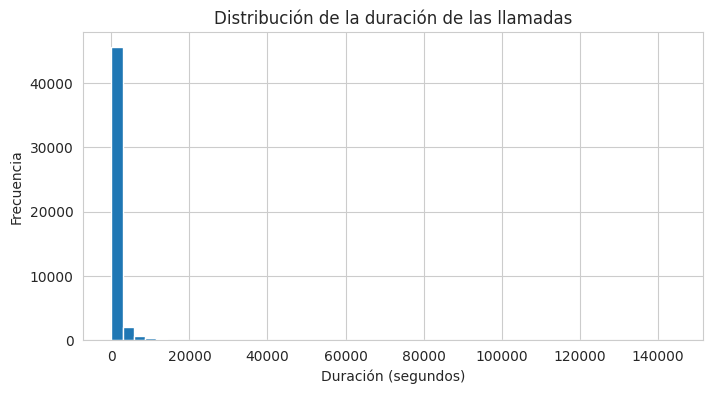

In [8]:
plt.figure(figsize=(8,4))
plt.hist(df['call_duration'], bins=50)
plt.title('Distribución de la duración de las llamadas')
plt.xlabel('Duración (segundos)'); plt.ylabel('Frecuencia')
plt.show()

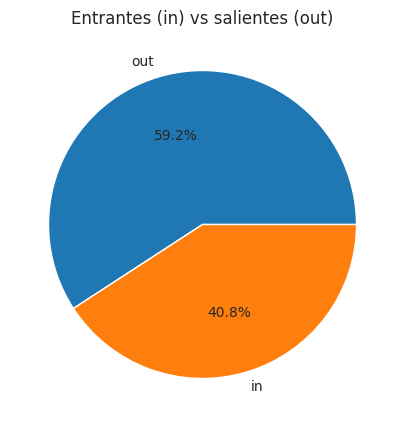

In [9]:
plt.figure(figsize=(5,5))
df['direction'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Entrantes (in) vs salientes (out)'); plt.ylabel('')
plt.show()

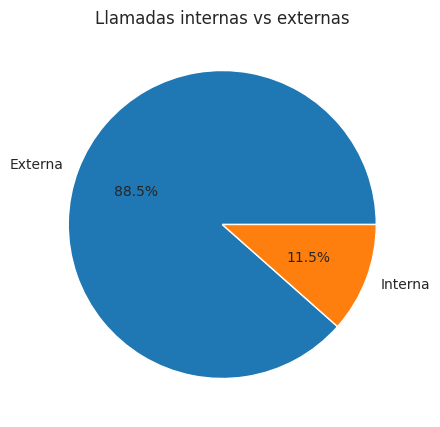

In [10]:
plt.figure(figsize=(5,5))
df['internal'].map({False:'Externa', True:'Interna'}).value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Llamadas internas vs externas'); plt.ylabel('')
plt.show()

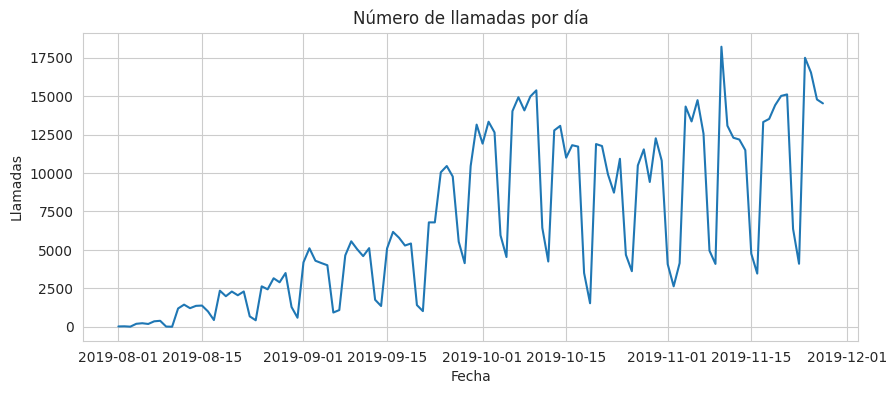

In [11]:
por_dia = df.groupby(df['date'].dt.date)['calls_count'].sum()
plt.figure(figsize=(10,4))
por_dia.plot()
plt.title('Número de llamadas por día'); plt.xlabel('Fecha'); plt.ylabel('Llamadas')
plt.show()

### Lo que veo
La mayoría de las llamadas duran poco y hay muchas más **salientes** que entrantes. Las llamadas **externas** dominan sobre las internas. El volumen por día sube con el tiempo, señal de que el servicio creció.


## Paso 5 — Métricas por operador
Aquí armo, para **cada operador**, los números que definen la eficacia:
- **perdidas_entrantes:** cuántas llamadas entrantes perdió.
- **espera_promedio:** cuánto hace esperar en promedio (segundos).
- **salientes:** cuántas llamadas salientes hizo.


In [12]:
# Solo llamadas con operador identificado
oper = df.dropna(subset=['operator_id']).copy()
oper['operator_id'] = oper['operator_id'].astype(int)

entrantes = oper[oper['direction'] == 'in']
salientes = oper[oper['direction'] == 'out']

resumen = pd.DataFrame({
    'perdidas_entrantes': entrantes[entrantes['is_missed_call']].groupby('operator_id')['calls_count'].sum(),
    'total_entrantes':    entrantes.groupby('operator_id')['calls_count'].sum(),
    'espera_promedio':    entrantes.groupby('operator_id')['wait_time'].mean(),
    'salientes':          salientes.groupby('operator_id')['calls_count'].sum(),
}).fillna(0)

resumen['tasa_perdidas'] = (resumen['perdidas_entrantes'] / resumen['total_entrantes']).replace([np.inf, np.nan], 0)
print('Operadores analizados:', resumen.shape[0])
resumen.describe().round(2)

Operadores analizados: 1092


,perdidas_entrantes,total_entrantes,espera_promedio,salientes,tasa_perdidas
count,1092.00,1092.00,1092.00,1092.00,1092.00
mean,0.85,85.90,39.78,557.09,0.01
std,3.21,301.67,82.87,2819.49,0.05
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,2.00,0.00
50%,0.00,5.00,19.00,33.00,0.00
75%,0.00,34.25,43.00,355.25,0.00
max,52.00,4766.00,1007.38,58977.00,1.00


### Un detalle importante
La mayoría de los operadores **no pierden** llamadas entrantes (la mediana de perdidas es 0). O sea, las llamadas perdidas se concentran en **pocos** operadores. Eso ya me dice dónde está el problema.


## Paso 6 — Identificar operadores ineficaces
Como el negocio no me da números exactos, uso **percentiles** para decir "los peores":
- **perdidas altas:** estar en el peor 25% (por encima del percentil 75).
- **espera alta:** igual, por encima del percentil 75.
- **pocas salientes:** entre los que sí hacen salientes, estar en el 25% más bajo.

Marco como **ineficaz** al operador que cumple los **dos criterios obligatorios** (perdidas altas **y** espera alta).


In [13]:
u_perdidas = resumen['perdidas_entrantes'].quantile(0.75)
u_espera   = resumen['espera_promedio'].quantile(0.75)
u_salientes = resumen[resumen['salientes'] > 0]['salientes'].quantile(0.25)
print(f'Umbrales -> perdidas > {u_perdidas:.0f} | espera > {u_espera:.0f}s | salientes < {u_salientes:.0f}')

resumen['crit_perdidas']  = resumen['perdidas_entrantes'] > u_perdidas
resumen['crit_espera']    = resumen['espera_promedio']    > u_espera
resumen['crit_salientes'] = (resumen['salientes'] > 0) & (resumen['salientes'] < u_salientes)

# Ineficaz = perdidas altas Y espera alta (los dos criterios obligatorios)
resumen['ineficaz'] = resumen['crit_perdidas'] & resumen['crit_espera']

print('Operadores ineficaces (perdidas altas Y espera alta):', int(resumen['ineficaz'].sum()))
print('De ellos, además con pocas salientes:', int((resumen['ineficaz'] & resumen['crit_salientes']).sum()))

Umbrales -> perdidas > 0 | espera > 43s | salientes < 11
Operadores ineficaces (perdidas altas Y espera alta): 141
De ellos, además con pocas salientes: 4


In [14]:
# Los peores operadores, ordenados
ineficaces = resumen[resumen['ineficaz']].sort_values(
    ['perdidas_entrantes', 'espera_promedio'], ascending=False)
ineficaces.head(10)[['perdidas_entrantes','total_entrantes','espera_promedio','salientes','tasa_perdidas']].round(1)

,perdidas_entrantes,total_entrantes,espera_promedio,salientes,tasa_perdidas
operator_id,,,,,
913942,52.0,2467.0,347.9,440.0,0.0
944226,30.0,180.0,153.6,109.0,0.2
940588,30.0,2127.0,127.2,67.0,0.0
885890,26.0,1244.0,120.3,58977.0,0.0
944216,24.0,235.0,160.9,133.0,0.1
951508,21.0,336.0,192.9,146.0,0.1
885876,20.0,992.0,100.2,58437.0,0.0
944220,18.0,265.0,187.4,221.0,0.1
940630,17.0,1985.0,166.0,127.0,0.0


### Conclusión del paso
Identifiqué un grupo claro de operadores ineficaces: pierden bastantes llamadas entrantes **y** hacen esperar mucho. Esta lista es justo lo que el supervisor necesita para actuar.


## Paso 7 — Prueba de hipótesis
Regla: si el **valor p < 0.05**, la diferencia es real (rechazo la hipótesis nula). Uso la prueba de **Mann-Whitney** porque los datos no son normales (muy dispares).


### Hipótesis 1 — ¿Los ineficaces atienden el mismo volumen que los eficaces?
- **H0:** los operadores ineficaces atienden el **mismo** número de llamadas entrantes que los eficaces.
- **H1:** atienden un número **diferente**.


In [15]:
g_inef = resumen[resumen['ineficaz']]['total_entrantes']
g_efic = resumen[~resumen['ineficaz']]['total_entrantes']
u = stats.mannwhitneyu(g_inef, g_efic, alternative='two-sided')
print(f'Mediana de entrantes -> ineficaces: {g_inef.median():.0f} | eficaces: {g_efic.median():.0f}')
print(f'valor p = {u.pvalue:.2e}')
print('Rechazo H0: la diferencia es real' if u.pvalue < 0.05 else 'No rechazo H0')

Mediana de entrantes -> ineficaces: 243 | eficaces: 2
valor p = 4.65e-70
Rechazo H0: la diferencia es real


**Conclusión H1:** rechazo H0. Los operadores ineficaces atienden **mucho más volumen** de llamadas entrantes que los eficaces. Es decir, la ineficacia se concentra en los operadores **más saturados**: no es que sean "malos" al azar, es que están sobrecargados. Esto ya sugiere una acción: **repartir mejor la carga**.


### Hipótesis 2 — ¿La tasa de llamadas perdidas depende del plan de tarifa?
- **H0:** la tasa de perdidas es **igual** entre el plan A y el plan B.
- **H1:** es **diferente**.


In [16]:
plan_op = oper.groupby('operator_id')['tariff_plan'].agg(lambda s: s.mode().iloc[0])
tmp = resumen.join(plan_op)
a = tmp[tmp['tariff_plan'] == 'A']['tasa_perdidas']
b = tmp[tmp['tariff_plan'] == 'B']['tasa_perdidas']
u2 = stats.mannwhitneyu(a, b, alternative='two-sided')
print(f'Tasa media de perdidas -> plan A: {a.mean():.3f} | plan B: {b.mean():.3f}')
print(f'valor p = {u2.pvalue:.2e}')
print('Rechazo H0: la diferencia es real' if u2.pvalue < 0.05 else 'No rechazo H0')

Tasa media de perdidas -> plan A: 0.009 | plan B: 0.013
valor p = 2.71e-01
No rechazo H0


**Conclusión H2:** no rechazo H0. **No hay diferencia** clara en las llamadas perdidas entre planes. Entonces el problema **no es el plan de tarifa**, sino los operadores concretos (la carga y el manejo de las llamadas).


## Paso 8 — Conclusiones y recomendaciones

**Lo que encontré:**
- Limpié los datos (quité duplicados, arreglé fechas y calculé el tiempo de espera).
- Las llamadas perdidas se concentran en **pocos** operadores: la mayoría no pierde llamadas.
- Identifiqué a los **operadores ineficaces** (muchas perdidas entrantes **y** espera larga).
- Los ineficaces atienden **mucho más volumen** (H1, p < 0.05): están saturados.
- La tasa de perdidas **no depende del plan** de tarifa (H2, no significativo).

**Mis recomendaciones para CallMeMaybe:**
1. **Repartir mejor la carga**: los operadores ineficaces están sobrecargados; balancear las llamadas entrantes ayudaría a bajar perdidas y espera.
2. **Vigilar a los operadores de la lista** con un tablero para el supervisor (perdidas y tiempo de espera).
3. **Poner una meta de tiempo de espera** máximo en llamadas entrantes.
4. **Revisar a los que hacen pocas salientes** cuando su rol sí lo pide.


## Fuentes consultadas
1. **Documentación de pandas** — `groupby`, `merge`, `drop_duplicates` (para armar las métricas por operador).
2. **Documentación de pandas** — `to_datetime` (para convertir la fecha con zona horaria).
3. **Documentación de SciPy** — `scipy.stats.mannwhitneyu` (para las pruebas de hipótesis con datos no normales).
4. **Documentación de Matplotlib** — histogramas y gráficos circulares.
5. **Material del Sprint 10 (Análisis de negocio)** — métricas, embudos y tasas.
6. **Material del Sprint 11 (Decisiones basadas en datos)** — pruebas de hipótesis y valor p.


## Dashboards y presentación

### Dashboards en Tableau Public
Publiqué dos dashboards (se cambia entre ellos con las pestañas de arriba):

- **Dashboard 1 — Duración y tipo:** histograma de la duración de la llamada + gráfico circular de internas vs externas + filtro por dirección (in / out).
  https://public.tableau.com/app/profile/carlos.orlando.meneses.corona/viz/CallMeMaybe-Operadoresineficaces/Dashboard1
- **Dashboard 2 — Llamadas por día y tipo:** histograma de llamadas por día + gráfico circular de internas vs externas + filtro por tipo de llamada (interna / externa).
  https://public.tableau.com/app/profile/carlos.orlando.meneses.corona/viz/CallMeMaybe-Operadoresineficaces/Dashboard2

### Presentación
La presentación ejecutiva está en el repositorio: `reports/Presentacion_CallMeMaybe.pdf`.


In [17]:
# Exporto los datos ya limpios para armar los dashboards en Tableau
resumen.reset_index().rename(columns={'index':'operator_id'}).to_csv('operadores_resumen.csv', index=False)
df.to_csv('llamadas_limpias.csv', index=False)
print('Listo: operadores_resumen.csv y llamadas_limpias.csv')

Listo: operadores_resumen.csv y llamadas_limpias.csv
